# Biased MF — scientific experiments and Task 2 model comparison

**Research question:** how do latent dimension and L2 regularization affect prediction accuracy,
overfitting and validation generalization on DAVIS and KIBA?

This executed notebook stores the experiment tables, unsmoothed learning-curve data and explanations
**inside the notebook**, using a frozen evidence snapshot in its JSON metadata. GitHub can display the
saved outputs directly. Rerunning cells needs this notebook, the two published MF checkpoints, existing
shared code and train/validation splits; **no external result CSVs, images or local backup are required**.

There are **no training/search calls and no test-split reads**. The historical tables are not fresh
experiments. Only the last section recomputes train/validation predictions from saved models.
The complete campaign had 73 physical fits; raw metadata includes all 73 metric rows and 3,275 epoch rows.
Missing metadata is an error rather than a reason to silently rerun experiments.

Jiaxin implemented Global Mean, Protein CF and Drug CF. WeiW0917 implemented Biased MF.
See [README](README.md), [scientific report](results/biased_mf/REPORT.md) and
[protocol](results/biased_mf/PROTOCOL.md). Results throughout are **validation results, not final test performance**.

In [1]:
from pathlib import Path
import hashlib
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

get_ipython().run_line_magic('matplotlib', 'inline')
TASK2 = Path.cwd() if Path.cwd().name == 'task2' else Path.cwd() / 'task2'
if str(TASK2.parent) not in sys.path:
    sys.path.insert(0, str(TASK2.parent))
EVIDENCE = json.loads((TASK2 / 'biased_mf.ipynb').read_text())['metadata']['biased_mf_evidence']
TABLES = {name: pd.DataFrame(rows) for name, rows in EVIDENCE['tables'].items()}
HISTORIES = {name: pd.DataFrame(values) for name, values in EVIDENCE['histories'].items()}
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_rows', 100)
pd.options.display.float_format = '{:.6f}'.format
METRICS = ['dataset', 'n_factors', 'regularization', 'learning_rate', 'seed',
           'parameter_count', 'train_mse', 'val_mse', 'train_val_mse_gap',
           'val_ci', 'val_hit_at_1', 'val_hit_at_5', 'best_epoch', 'epochs_run']

def show_table(name, columns=None):
    frame = TABLES[name]
    display(frame if columns is None else frame[columns])
    return frame

def show_plot(fig):
    fig.tight_layout()
    display(fig)
    plt.close(fig)

def curves(rows, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for _, row in rows.iterrows():
        trace = HISTORIES[row.run_id]
        label = f'F={int(row.n_factors)}, lambda={row.regularization:g}, alpha={row.learning_rate:g}'
        for ax, metric in zip(axes, ['train_mse', 'val_mse']):
            line, = ax.plot(trace.epoch, trace[metric], label=label)
            point = trace.loc[trace.epoch.eq(row.best_epoch)].iloc[0]
            ax.scatter(point.epoch, point[metric], color=line.get_color(), s=22)
            ax.set(xlabel='Epoch', ylabel=metric.replace('_', ' ').upper())
    axes[1].legend(fontsize=7)
    fig.suptitle(title + ' — dots mark selected epochs')
    show_plot(fig)

assert len(TABLES['all_physical_runs']) == 73
assert len(HISTORIES) == 73 and sum(map(len, HISTORIES.values())) == 3275
print('Loaded 73 recorded fits and 3,275 epoch rows from this notebook; no experiments run.')
display(TABLES['data_integrity'][['dataset', 'split', 'rows', 'drugs', 'targets',
                                'min_affinity', 'max_affinity']])

Loaded 73 recorded fits and 3,275 epoch rows from this notebook; no experiments run.


,dataset,split,rows,drugs,targets,min_affinity,max_affinity
0,davis,train,18040,68,379,5.000000,10.619789
1,davis,val,3865,68,379,5.000000,10.124939
2,kiba,train,82359,2068,229,0.000000,17.200179
3,kiba,val,17648,1967,228,1.100000,16.100000


## 1. Model and experimental protocol

For known drug $i$ and target $j$:

$$\hat y_{ij}=\mu+b_i+c_j+p_i^\top q_j.$$

The mean and ID mappings come only from training. SMILES/sequences are **identifiers**, not encoded
chemical/biological features. Biases start at zero; factors use seeded Normal(0,0.01²) draws.
Only observed training pairs contribute to:

$$L=\frac{\sum_{(i,j)\in\Omega}(\hat y_{ij}-y_{ij})^2+
\lambda(\|b\|^2+\|c\|^2+\|P\|_F^2+\|Q\|_F^2)}{2N}.$$

Batch gradients are mean data gradients plus **lambda/N times each parameter**. Repeated IDs are
accumulated, and both factor gradients use pre-update values. Adam has beta1=.9, beta2=.999 and epsilon=1e-8.
Batch size=2048 and patience=10 throughout. Epoch zero is eligible; the best validation-MSE parameters
are restored after stopping. Validation labels never enter gradients. No labels are normalized or clipped:
DAVIS is already pKd and KIBA uses the supplied transformed scale.

| Stage | Variable | Fixed conditions / selection |
|---|---|---|
| Capacity | F=8,16,32,64,128; lambda=0,.01 | alpha=.005, seed=42, cap=100 |
| Overfitting | Recorded training/validation curves | No new fits; gaps alone do not prove overfitting |
| F–lambda interaction | Five F values × lambda=0,.01,.1,1,10 | alpha=.005, seed=42, cap=100 |
| Learning rate | alpha=.001,.003,.005,.01 | Two best F–lambda pairs per dataset by validation MSE |
| Robustness | seeds=42,123,2026 | Two frozen full configurations per dataset |

Final hyperparameters minimize **three-seed mean validation MSE** among the shortlist.
The published checkpoint always uses seed 42, not the best individual seed.
Historical configurations lacking verifiable source/data/state provenance were rerun and labeled;
verified campaign states were reused between stages. There were 70 base fits plus three cap extensions.

## 2. Jiaxin's baselines and the combined validation comparison

- **Global Mean:** predict the fixed training mean for every query. It has no personalized ranking;
  tied predictions give global CI=.5 when actual scores differ.
- **Protein CF:** compute pairwise Pearson similarity from common training drugs, discard negative
  correlation, shrink by `common_count/(common_count+10)`, and exclude self-neighbors. For a query drug,
  combine its observed deviations on similar targets around the query target's training mean.
  If neighbors are unavailable, use that target mean; an unknown target uses the global mean.
- **Drug CF:** exchange drug/protein roles in the same CF engine. Similar drugs are compared across
  common training proteins; predictions use drug means and observed scores on the query target.
  With no usable neighbors use the known drug's mean; an unknown drug uses the global mean.

KNN similarity uses observed affinity patterns, **not molecular fingerprints or sequence alignment**.
Jiaxin tunes K in {5,10,20,30} and minimum overlap in {2,5,10} by validation MSE, with shrinkage 10.
Selected K: Protein CF DAVIS=10/KIBA=5; Drug CF DAVIS=5/KIBA=10. All selected minimum overlaps are 2.

Her rows below are the recorded notebook outputs at Git commit `21ade81`, not recomputed experiments.
Only training/validation columns are copied. MF rows are the saved seed-42 campaign selection.
Jiaxin's printed numbers are already rounded; no extra precision or significance is implied.

In [2]:
comparison = TABLES['jiaxin_recorded_validation'].copy()
mf_rows = TABLES['final_selection'].copy()
mf_rows['model'] = 'Biased MF'
mf_rows['contributor'] = 'WeiW0917'
columns = ['dataset', 'model', 'contributor', 'train_mse', 'val_mse', 'val_ci', 'val_hit_at_1', 'val_hit_at_5']
comparison = pd.concat([comparison[columns], mf_rows[columns]], ignore_index=True)
for dataset in ['davis', 'kiba']:
    print(dataset.upper())
    display(comparison.loc[comparison.dataset.eq(dataset)].sort_values('val_mse').reset_index(drop=True))

DAVIS


,dataset,model,contributor,train_mse,val_mse,val_ci,val_hit_at_1,val_hit_at_5
0,davis,Biased MF,WeiW0917,0.026219,0.259842,0.873175,0.338235,0.720588
1,davis,Protein CF,Jiaxin,0.143402,0.282732,0.866063,0.323529,0.647059
2,davis,Drug CF,Jiaxin,0.288737,0.322968,0.856107,0.308824,0.676471
3,davis,Global Mean,Jiaxin,0.649827,0.675120,0.500000,0.102941,0.132353


KIBA


,dataset,model,contributor,train_mse,val_mse,val_ci,val_hit_at_1,val_hit_at_5
0,kiba,Biased MF,WeiW0917,0.023247,0.188761,0.848053,0.690391,0.952211
1,kiba,Drug CF,Jiaxin,0.117061,0.209019,0.848886,0.665989,0.934926
2,kiba,Protein CF,Jiaxin,0.222928,0.239772,0.826530,0.620234,0.921708
3,kiba,Global Mean,Jiaxin,0.693327,0.687805,0.500000,0.375699,0.717844


**Interpretation:** Biased MF has the lowest validation MSE on both datasets: approximately 8.10% lower
than the best DAVIS KNN (Protein CF) and 9.69% lower than the best KIBA KNN (Drug CF).
It leads all four displayed validation metrics on DAVIS. On KIBA, Drug CF has slightly higher global CI
(0.848886 vs 0.848053), so MF does not dominate every criterion. Low training error alone is not evidence
of better generalization. The team still needs to agree on frozen final models before final evaluation.

## 3. Capacity and overfitting (Stages 1–2)

Learned parameter count is `(number of drugs + number of targets) * (F+1)`; the fixed mean is excluded.
Increasing F lowers both training and best-validation MSE at every tested step under lambda=0 and .01.
Meanwhile, gaps grow and the selected epoch occurs earlier. There is no inverted-U best-validation
capacity curve in this tested range. All 20 curves subsequently improve training fit while worsening
validation MSE, supporting restoration of the earlier checkpoint rather than choosing by gap size.

The overfitting indicator requires a final training decrease and validation increase both exceeding 1e-6
relative to the selected epoch. Underfitting labels are descriptive peer comparisons, not hypothesis tests.
Unregularized results do not automatically select final F. DAVIS has only 68 drug rows, so F=128 changes
redundant parameterization/optimization as well as capacity; its interaction matrix cannot have rank 128.

**Capacity-plot caption:** color distinguishes training (blue) from validation (orange). Lambda=0 uses
broad solid lines and large open circles drawn first; lambda=0.01 uses thin dashed lines and small
crosses drawn above them. Both remain visible when their positions nearly coincide. No jitter or
score offsets are applied. Weak regularization produces very small observed differences here under
the implemented objective `(SSE + lambda * sum(parameter^2))/(2N)`, whose L2 gradient is `lambda/N * parameter`.

**Supplementary difference-plot caption:** delta MSE = MSE(lambda=0.01) minus MSE(lambda=0), paired
at the same F and evaluated at each configuration's best validation epoch. Negative delta means lower
MSE with weak L2; positive delta means higher MSE. The expanded scientific-notation axis reveals small
differences hidden by the absolute-MSE scale; it is not a change to labels or evidence of statistical
significance. Weak L2 does not improve every setting (DAVIS F=8 and KIBA F=32 have positive validation deltas).

,dataset,n_factors,regularization,learning_rate,seed,parameter_count,train_mse,val_mse,train_val_mse_gap,val_ci,val_hit_at_1,val_hit_at_5,best_epoch,epochs_run,overfit_curve_evidence,underfit_evidence
0,davis,8,0.000000,0.005000,42,4023,0.182918,0.323579,0.140660,0.849838,0.250000,0.558824,30,40,True,both errors higher than validation-best peer; ...
1,davis,8,0.010000,0.005000,42,4023,0.182884,0.323905,0.141021,0.849725,0.264706,0.558824,30,40,True,both errors higher than validation-best peer; ...
2,davis,16,0.000000,0.005000,42,7599,0.133496,0.299793,0.166298,0.858350,0.323529,0.661765,24,34,True,both errors higher than validation-best peer; ...
3,davis,16,0.010000,0.005000,42,7599,0.133477,0.299665,0.166188,0.858418,0.338235,0.661765,24,34,True,both errors higher than validation-best peer; ...
4,davis,32,0.000000,0.005000,42,14751,0.073101,0.278691,0.205590,0.861124,0.367647,0.720588,23,33,True,both errors higher than validation-best peer; ...
5,davis,32,0.010000,0.005000,42,14751,0.073244,0.278625,0.205381,0.861187,0.367647,0.720588,23,33,True,both errors higher than validation-best peer; ...
6,davis,64,0.000000,0.005000,42,29055,0.049098,0.271701,0.222603,0.866198,0.352941,0.676471,16,26,True,both errors higher than validation-best peer; ...
7,davis,64,0.010000,0.005000,42,29055,0.049215,0.271677,0.222462,0.866220,0.352941,0.676471,16,26,True,both errors higher than validation-best peer; ...
8,davis,128,0.000000,0.005000,42,57663,0.023977,0.268324,0.244348,0.863863,0.397059,0.705882,14,24,True,not established
9,davis,128,0.010000,0.005000,42,57663,0.024080,0.268317,0.244237,0.863917,0.397059,0.705882,14,24,True,not established


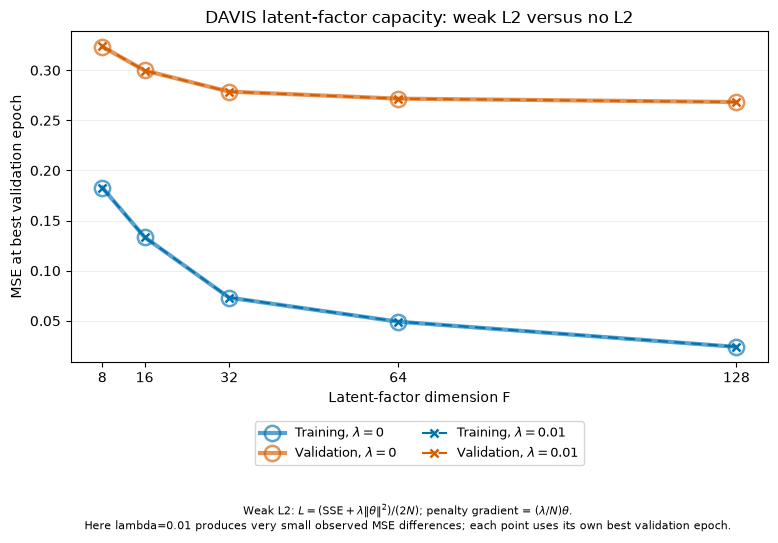

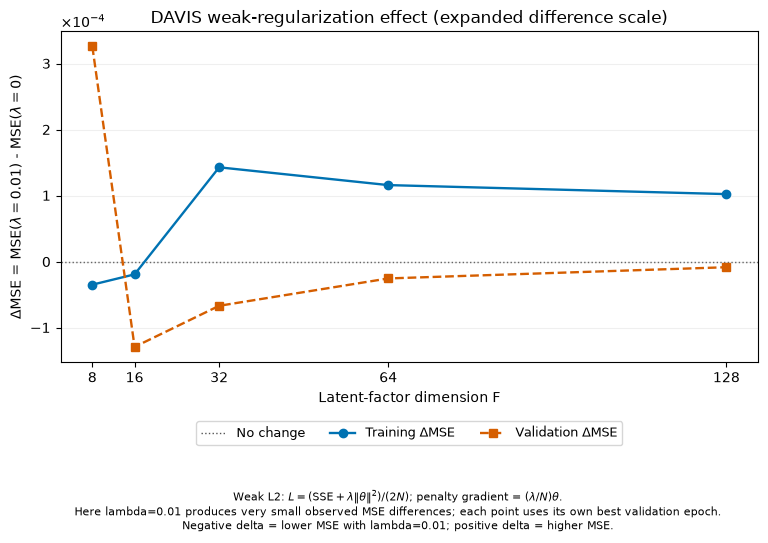

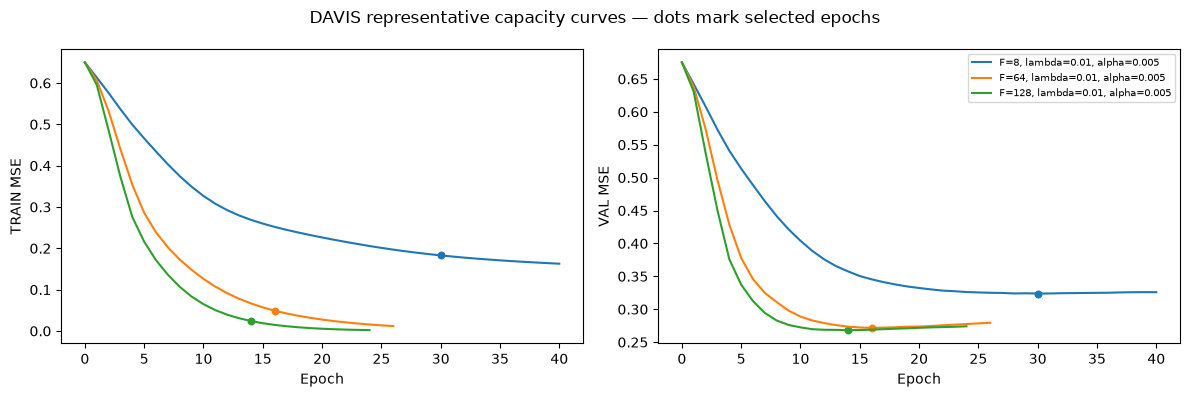

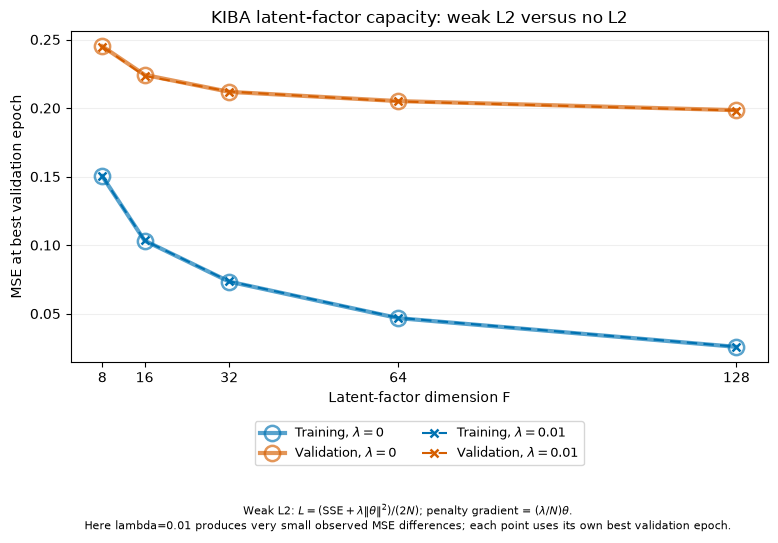

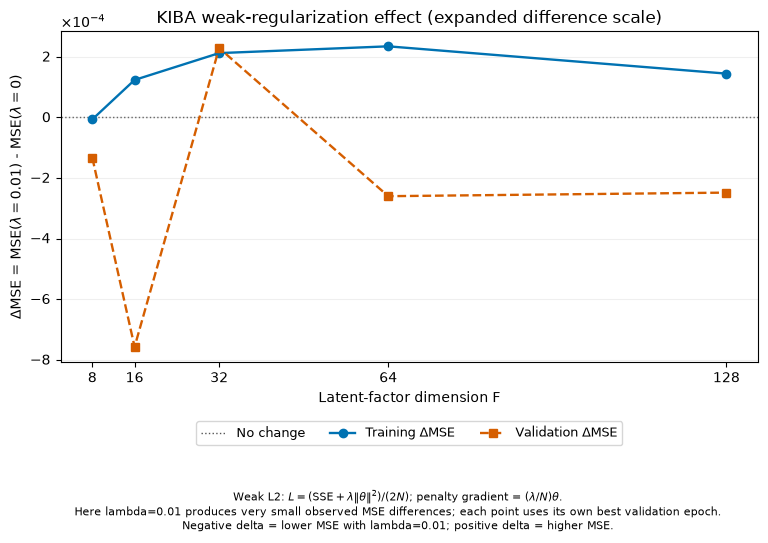

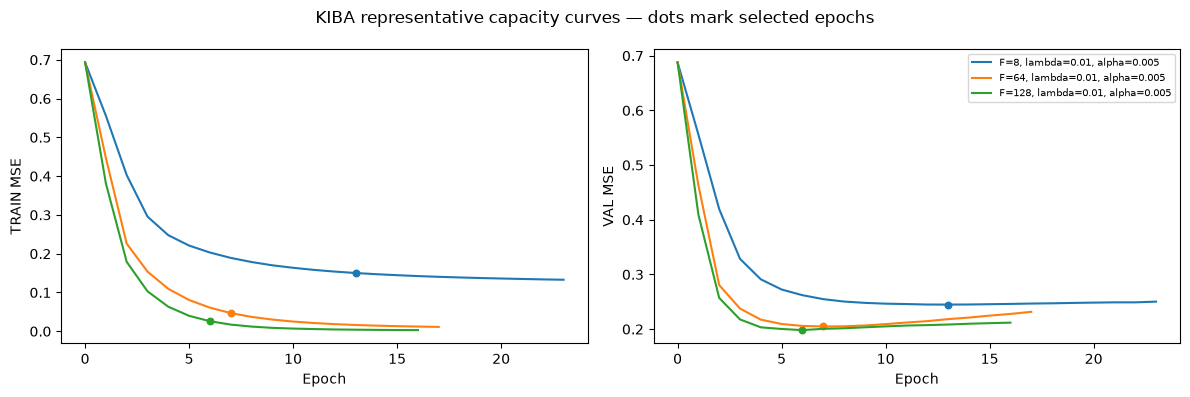

Exact paired differences from recorded scores; no fitting or score offsets:


,dataset,n_factors,train_delta_mse,val_delta_mse
0,davis,8,-3.415644e-05,+3.265698e-04
1,davis,16,-1.853605e-05,-1.282899e-04
2,davis,32,+1.434579e-04,-6.613198e-05
3,davis,64,+1.165606e-04,-2.471726e-05
4,davis,128,+1.029156e-04,-7.752033e-06
5,kiba,8,-6.791621e-06,-1.333219e-04
6,kiba,16,+1.233221e-04,-7.573651e-04
7,kiba,32,+2.118910e-04,+2.285298e-04
8,kiba,64,+2.342514e-04,-2.601858e-04
9,kiba,128,+1.441939e-04,-2.484126e-04


,dataset,n_factors,regularization,best_epoch,epochs_run,train_mse,train_mse_last,val_mse,val_mse_last,overfit_curve_evidence
0,davis,8,0.000000,30,40,0.182918,0.163033,0.323579,0.325744,True
1,davis,8,0.010000,30,40,0.182884,0.162775,0.323905,0.325980,True
2,davis,16,0.000000,24,34,0.133496,0.097130,0.299793,0.305953,True
3,davis,16,0.010000,24,34,0.133477,0.097118,0.299665,0.305646,True
4,davis,32,0.000000,23,33,0.073101,0.037846,0.278691,0.290461,True
5,davis,32,0.010000,23,33,0.073244,0.037906,0.278625,0.290192,True
6,davis,64,0.000000,16,26,0.049098,0.011791,0.271701,0.279637,True
7,davis,64,0.010000,16,26,0.049215,0.011857,0.271677,0.279497,True
8,davis,128,0.000000,14,24,0.023977,0.002069,0.268324,0.274202,True
9,davis,128,0.010000,14,24,0.024080,0.002098,0.268317,0.274115,True


In [3]:
from task2.run_biased_mf import capacity_figures
capacity = show_table('stage1_capacity', METRICS + ['overfit_curve_evidence', 'underfit_evidence'])
capacity_deltas = []
for dataset in ['davis', 'kiba']:
    subset = capacity.loc[capacity.dataset.eq(dataset)]
    absolute, difference, delta = capacity_figures(capacity, dataset)
    for figure in [absolute, difference]:
        display(figure)  # Preserve the helper's caption/legend layout.
        plt.close(figure)
    capacity_deltas.append(delta)
    curves(subset.loc[subset.regularization.eq(.01) & subset.n_factors.isin([8, 64, 128])],
           dataset.upper() + ' representative capacity curves')
print('Exact paired differences from recorded scores; no fitting or score offsets:')
display(pd.concat(capacity_deltas, ignore_index=True).style.format(
    {'train_delta_mse': '{:+.6e}', 'val_delta_mse': '{:+.6e}'}))
display(capacity[['dataset', 'n_factors', 'regularization', 'best_epoch', 'epochs_run',
                  'train_mse', 'train_mse_last', 'val_mse', 'val_mse_last', 'overfit_curve_evidence']])

## 4. L2 and F–lambda interaction (Stage 3)

All 25 conditions per dataset are shown below. Moderate regularization generally helps, but not monotonically.
DAVIS prefers lambda=1 for F=16–128, while F=8 prefers 10 within the 100-epoch budget. KIBA prefers lambda=1
at every F, but its preferred F changes from 128 to 32 at lambda=10. Increasing lambda from 1 to 10 at
F=128 raises both training and validation errors, consistent with excessive shrinkage at that setting.

Four strong-penalty core cells remain improving at epoch 100: DAVIS F=8,16,32/lambda=10 and KIBA
F=8/lambda=10. They are flagged, not described as converged. Stage 3 retains its fixed budget;
the extension protocol applies to refinement/robustness. Heatmaps use separately labeled scales,
and zero-inclusive lambda plots use categorical spacing. Curves use raw recorded points, not smoothing.

,dataset,n_factors,regularization,learning_rate,seed,parameter_count,train_mse,val_mse,train_val_mse_gap,val_ci,val_hit_at_1,val_hit_at_5,best_epoch,epochs_run,cap_still_improving,underfit_evidence
0,davis,8,0.000000,0.005000,42,4023,0.182918,0.323579,0.140660,0.849838,0.250000,0.558824,30,40,False,not established
1,davis,8,0.010000,0.005000,42,4023,0.182884,0.323905,0.141021,0.849725,0.264706,0.558824,30,40,False,not established
2,davis,8,0.100000,0.005000,42,4023,0.183051,0.323780,0.140729,0.850016,0.264706,0.558824,30,40,False,not established
3,davis,8,1.000000,0.005000,42,4023,0.151367,0.315412,0.164045,0.846086,0.220588,0.602941,56,66,False,not established
4,davis,8,10.000000,0.005000,42,4023,0.209456,0.309103,0.099647,0.867062,0.250000,0.544118,98,100,True,budget-limited; insufficient evidence
5,davis,16,0.000000,0.005000,42,7599,0.133496,0.299793,0.166298,0.858350,0.323529,0.661765,24,34,False,both errors higher than validation-best peer; ...
6,davis,16,0.010000,0.005000,42,7599,0.133477,0.299665,0.166188,0.858418,0.338235,0.661765,24,34,False,both errors higher than validation-best peer; ...
7,davis,16,0.100000,0.005000,42,7599,0.133907,0.298762,0.164855,0.859074,0.338235,0.661765,24,34,False,both errors higher than validation-best peer; ...
8,davis,16,1.000000,0.005000,42,7599,0.102858,0.292319,0.189461,0.859969,0.308824,0.647059,34,44,False,not established
9,davis,16,10.000000,0.005000,42,7599,0.192663,0.304769,0.112106,0.870060,0.294118,0.558824,98,100,True,budget-limited; insufficient evidence


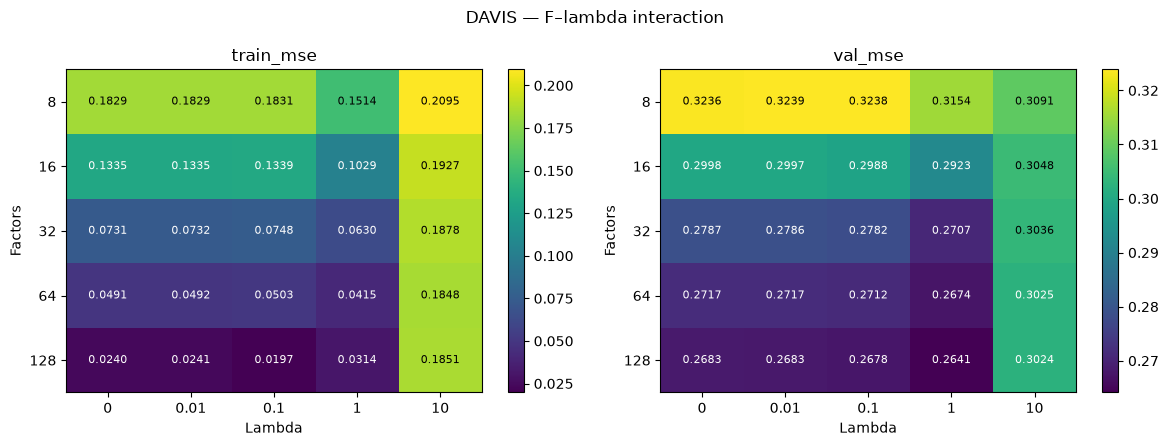

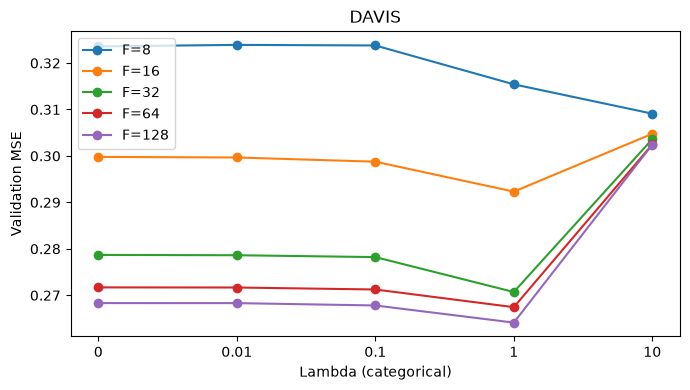

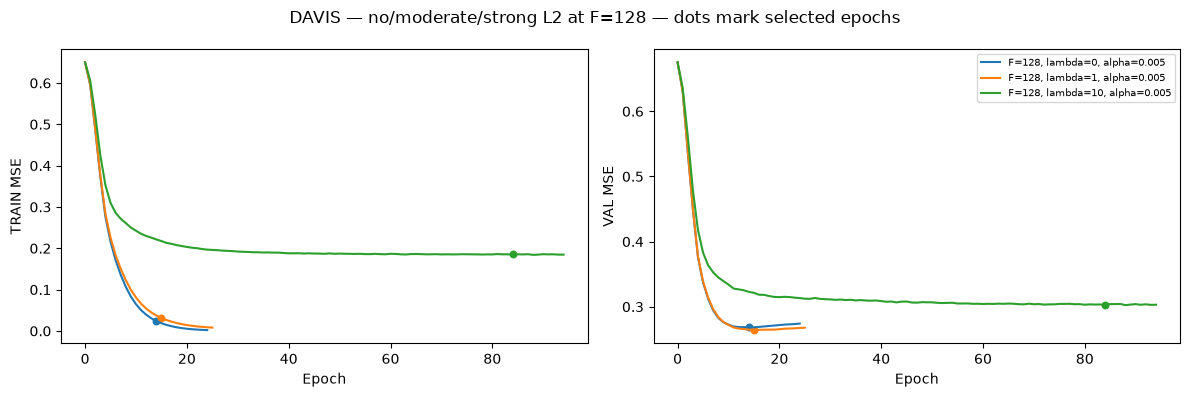

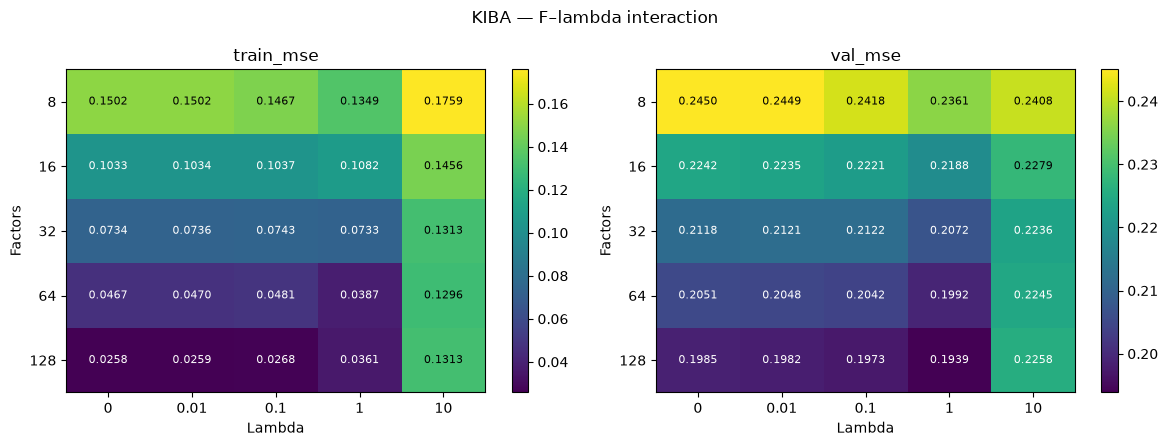

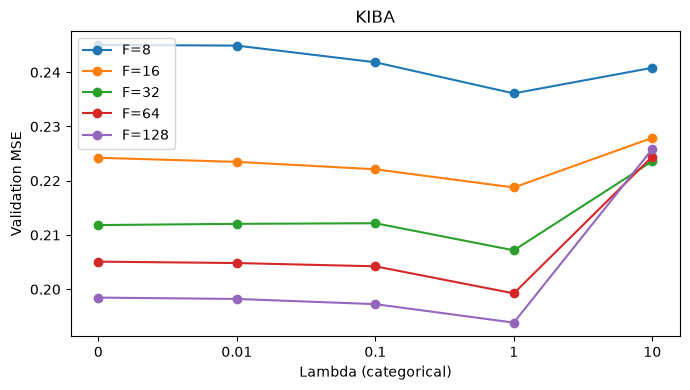

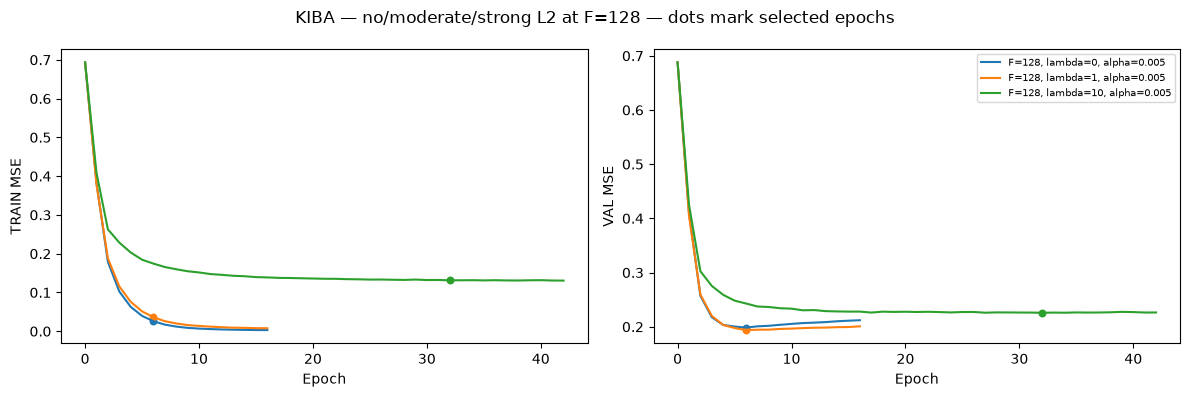

Best lambda for each F:


,dataset,n_factors,regularization,learning_rate,seed,parameter_count,train_mse,val_mse,train_val_mse_gap,val_ci,val_hit_at_1,val_hit_at_5,best_epoch,epochs_run,cap_still_improving
0,kiba,128,1.000000,0.005000,42,296313,0.036058,0.193851,0.157793,0.845344,0.686324,0.947128,6,16,False
1,kiba,64,1.000000,0.005000,42,149305,0.038660,0.199242,0.160582,0.842222,0.689883,0.949161,9,19,False
2,kiba,32,1.000000,0.005000,42,75801,0.073270,0.207177,0.133907,0.838417,0.670056,0.945602,10,20,False
3,kiba,16,1.000000,0.005000,42,39049,0.108153,0.218759,0.110607,0.836363,0.655313,0.927300,12,22,False
4,kiba,8,1.000000,0.005000,42,20673,0.134901,0.236101,0.101200,0.827344,0.624809,0.922725,22,32,False
5,davis,128,1.000000,0.005000,42,57663,0.031364,0.264120,0.232755,0.868816,0.397059,0.735294,15,25,False
6,davis,64,1.000000,0.005000,42,29055,0.041480,0.267443,0.225963,0.867500,0.338235,0.735294,20,30,False
7,davis,32,1.000000,0.005000,42,14751,0.062952,0.270710,0.207757,0.864980,0.382353,0.720588,28,38,False
8,davis,16,1.000000,0.005000,42,7599,0.102858,0.292319,0.189461,0.859969,0.308824,0.647059,34,44,False
9,davis,8,10.000000,0.005000,42,4023,0.209456,0.309103,0.099647,0.867062,0.250000,0.544118,98,100,True


Best F for each lambda:


,dataset,n_factors,regularization,learning_rate,seed,parameter_count,train_mse,val_mse,train_val_mse_gap,val_ci,val_hit_at_1,val_hit_at_5,best_epoch,epochs_run
0,kiba,128,1.000000,0.005000,42,296313,0.036058,0.193851,0.157793,0.845344,0.686324,0.947128,6,16
1,kiba,128,0.100000,0.005000,42,296313,0.026755,0.197257,0.170502,0.840760,0.686833,0.945094,6,16
2,kiba,128,0.010000,0.005000,42,296313,0.025903,0.198213,0.172310,0.839677,0.681240,0.945602,6,16
3,kiba,128,0.000000,0.005000,42,296313,0.025759,0.198461,0.172702,0.839427,0.682766,0.944586,6,16
4,kiba,32,10.000000,0.005000,42,75801,0.131337,0.223612,0.092274,0.844419,0.655821,0.931368,59,69
5,davis,128,1.000000,0.005000,42,57663,0.031364,0.264120,0.232755,0.868816,0.397059,0.735294,15,25
6,davis,128,0.100000,0.005000,42,57663,0.019729,0.267810,0.248081,0.864306,0.382353,0.720588,15,25
7,davis,128,0.010000,0.005000,42,57663,0.024080,0.268317,0.244237,0.863917,0.397059,0.705882,14,24
8,davis,128,0.000000,0.005000,42,57663,0.023977,0.268324,0.244348,0.863863,0.397059,0.705882,14,24
9,davis,128,10.000000,0.005000,42,57663,0.185087,0.302430,0.117342,0.871494,0.308824,0.558824,84,94


Historical lambda=100 evidence (supplement only, not new campaign fits):


,dataset,n_factors,regularization,train_mse,val_mse,best_epoch
0,davis,64,100.000000,0.448585,0.487024,72
1,kiba,64,100.000000,0.503401,0.503147,24


In [4]:
joint = show_table('stage3_interaction', METRICS + ['cap_still_improving', 'underfit_evidence'])
for dataset in ['davis', 'kiba']:
    subset = joint.loc[joint.dataset.eq(dataset)]
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    for ax, metric in zip(axes, ['train_mse', 'val_mse']):
        matrix = subset.pivot(index='n_factors', columns='regularization', values=metric)
        image = ax.imshow(matrix, aspect='auto', cmap='viridis')
        ax.set_xticks(range(len(matrix.columns)), [f'{x:g}' for x in matrix.columns])
        ax.set_yticks(range(len(matrix.index)), matrix.index)
        ax.set(xlabel='Lambda', ylabel='Factors', title=metric)
        for i in range(len(matrix.index)):
            for j in range(len(matrix.columns)):
                value = matrix.iloc[i, j]
                color = 'black' if image.norm(value) > .65 else 'white'
                ax.text(j, i, f'{value:.4f}', ha='center', va='center', color=color, fontsize=8)
        fig.colorbar(image, ax=ax)
    fig.suptitle(dataset.upper() + ' — F–lambda interaction')
    show_plot(fig)
    fig, ax = plt.subplots(figsize=(7, 4))
    for factors, group in subset.groupby('n_factors'):
        group = group.sort_values('regularization')
        ax.plot(range(len(group)), group.val_mse, 'o-', label=f'F={int(factors)}')
    ax.set_xticks(range(5), ['0', '0.01', '0.1', '1', '10'])
    ax.set(xlabel='Lambda (categorical)', ylabel='Validation MSE', title=dataset.upper())
    ax.legend()
    show_plot(fig)
    curves(subset.loc[subset.n_factors.eq(128) & subset.regularization.isin([0, 1, 10])],
           dataset.upper() + ' — no/moderate/strong L2 at F=128')
print('Best lambda for each F:')
best_penalties = show_table('stage3_best_lambda_per_f', METRICS + ['cap_still_improving'])
print('Best F for each lambda:')
best_factors = show_table('stage3_best_f_per_lambda', METRICS)
print('Historical lambda=100 evidence (supplement only, not new campaign fits):')
supplement = show_table('historical_lambda100_supplement',
                       ['dataset', 'n_factors', 'regularization', 'train_mse', 'val_mse', 'best_epoch'])

## 5. Adam learning-rate refinement (Stage 4)

Stage 3 selects DAVIS (F=128,lambda=1)/(F=64,lambda=1) and KIBA
(F=128,lambda=1)/(F=128,lambda=.1). Alpha=.001,.003,.005,.01 is tried for each pair.
Adam adapts coefficient-wise scaling but still depends on its base learning rate.

**Predeclared extension:** a condition reaching epoch 100 with a new validation minimum in its last ten
epochs is replayed from the same seed with cap=300 and unchanged patience. All first 101 history rows
must match exactly. This rule applies to every rate and robustness seed; no cap above 300 is used.
DAVIS F64/lambda=1/alpha=.001 improves from 0.260110 at epoch 100 to 0.259899 at epoch 105,
then stops at 115. Its computational cost includes both the 100-epoch prefix and the 115-epoch replay.

Alpha=.001 gives the best validation result in each refined family, but needs more updates. All final
rate comparisons stop by patience; none failed numerically. Different rates are not assumed to reach
the same solution. No SGD comparison or expanded rate grid was performed.

,dataset,n_factors,regularization,learning_rate,seed,parameter_count,train_mse,val_mse,train_val_mse_gap,val_ci,val_hit_at_1,val_hit_at_5,best_epoch,epochs_run,total_optimizer_updates,updates_to_best,extension_applied,cap_still_improving
0,kiba,128,1.000000,0.001000,42,296313,0.023247,0.188761,0.165513,0.848053,0.690391,0.952211,34,44,1804,1394,False,False
1,kiba,128,1.000000,0.003000,42,296313,0.026268,0.189752,0.163484,0.846641,0.681749,0.949161,11,21,861,451,False,False
2,kiba,128,1.000000,0.005000,42,296313,0.036058,0.193851,0.157793,0.845344,0.686324,0.947128,6,16,656,246,False,False
3,kiba,128,1.000000,0.010000,42,296313,0.033482,0.203476,0.169995,0.835202,0.668022,0.943569,4,14,574,164,False,False
4,kiba,128,0.100000,0.001000,42,296313,0.028151,0.191518,0.163367,0.846433,0.684799,0.946111,27,37,1517,1107,False,False
5,kiba,128,0.100000,0.003000,42,296313,0.030110,0.193768,0.163657,0.844014,0.676157,0.947636,9,19,779,369,False,False
6,kiba,128,0.100000,0.005000,42,296313,0.026755,0.197257,0.170502,0.840760,0.686833,0.945094,6,16,656,246,False,False
7,kiba,128,0.100000,0.010000,42,296313,0.026098,0.209704,0.183606,0.828988,0.669548,0.945094,4,14,574,164,False,False
8,davis,128,1.000000,0.001000,42,57663,0.026219,0.259842,0.233622,0.873175,0.338235,0.720588,74,84,756,666,False,False
9,davis,128,1.000000,0.003000,42,57663,0.028465,0.263022,0.234557,0.870104,0.367647,0.735294,25,35,315,225,False,False


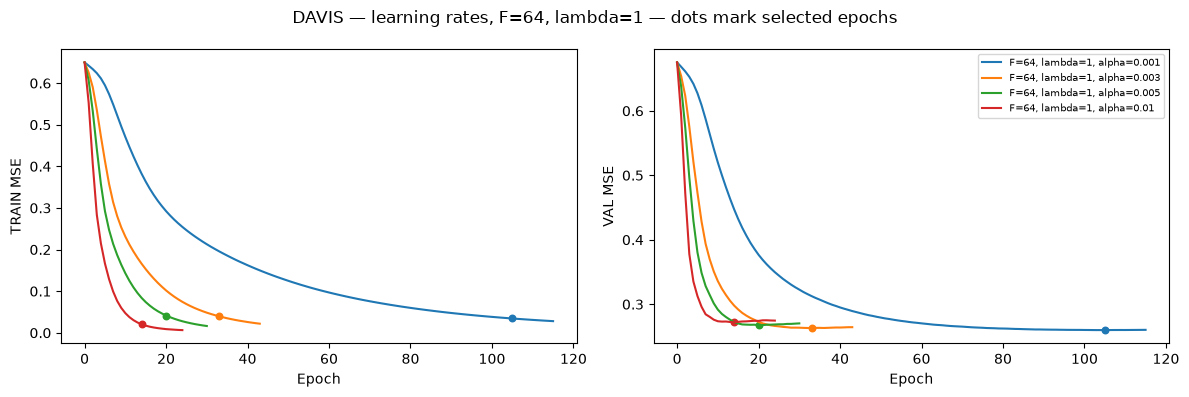

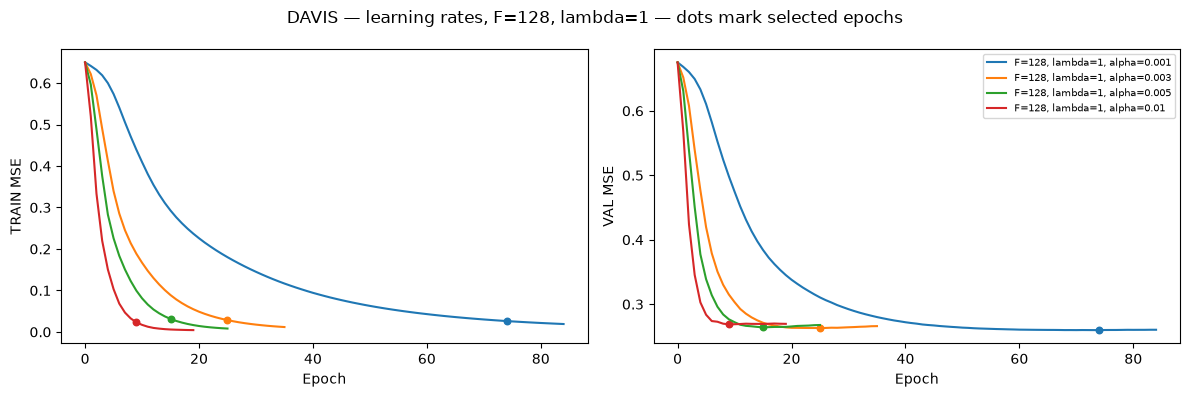

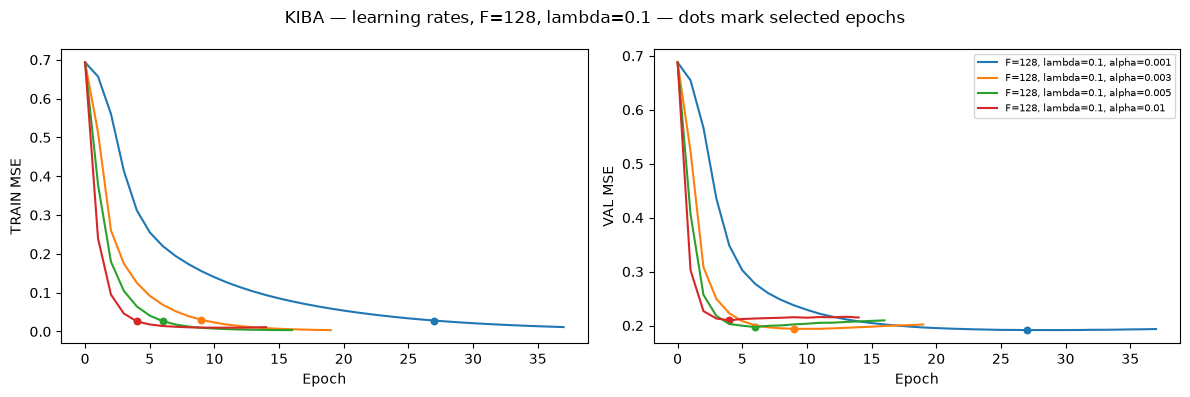

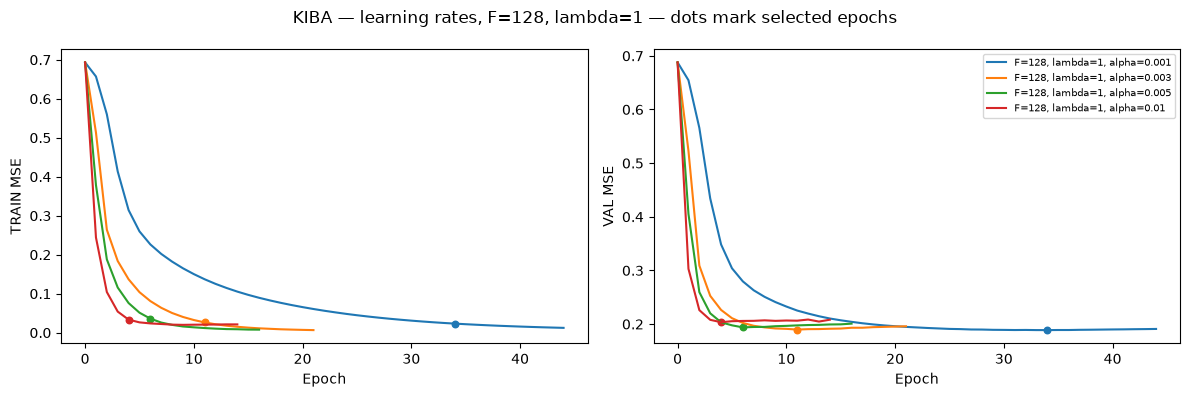

In [5]:
rates = show_table('stage4_rates', METRICS + ['total_optimizer_updates', 'updates_to_best',
                                           'extension_applied', 'cap_still_improving'])
for (dataset, factors, penalty), group in rates.groupby(['dataset', 'n_factors', 'regularization']):
    curves(group.sort_values('learning_rate'),
           f'{dataset.upper()} — learning rates, F={int(factors)}, lambda={penalty:g}')

## 6. Three-seed robustness and selection (Stage 5)

Two full configurations per dataset were frozen before running seeds 123 and 2026; seed 42 was reused.
Final configuration selection uses mean validation MSE over all three seeds, with sample SD (ddof=1).
This is further validation selection, not independent confirmation. Handoff seed is always 42.

Both datasets select F=128, lambda=1, alpha=.001. DAVIS F128 has better mean MSE but greater seed
variability and lower mean Hit@K than F64. KIBA alpha=.001 beats .003 on each observed seed, but the
mean difference is small relative to variation. Three seeds are limited stability evidence, not proof.
The best DAVIS individual seed was 123; it was **not** substituted for seed 42.

Two additional DAVIS F64/.001 robustness runs triggered the cap rule: seed 123 selected epoch 112;
seed 2026 found no improvement and kept epoch 97, stopping at 107. Extensions need not improve results.

,dataset,n_factors,regularization,learning_rate,seed,parameter_count,train_mse,val_mse,train_val_mse_gap,val_ci,val_hit_at_1,val_hit_at_5,best_epoch,epochs_run,max_epochs,extension_applied
0,kiba,128,1.000000,0.001000,42,296313,0.023247,0.188761,0.165513,0.848053,0.690391,0.952211,34,44,100,False
1,kiba,128,1.000000,0.001000,123,296313,0.026763,0.189480,0.162717,0.848731,0.682766,0.949161,32,42,100,False
2,kiba,128,1.000000,0.001000,2026,296313,0.026273,0.191325,0.165052,0.848831,0.693442,0.945602,32,42,100,False
3,kiba,128,1.000000,0.003000,42,296313,0.026268,0.189752,0.163484,0.846641,0.681749,0.949161,11,21,100,False
4,kiba,128,1.000000,0.003000,123,296313,0.021544,0.189975,0.168431,0.847491,0.679207,0.949670,12,22,100,False
5,kiba,128,1.000000,0.003000,2026,296313,0.026353,0.192269,0.165916,0.846370,0.678699,0.946619,11,21,100,False
6,davis,128,1.000000,0.001000,42,57663,0.026219,0.259842,0.233622,0.873175,0.338235,0.720588,74,84,100,False
7,davis,128,1.000000,0.001000,123,57663,0.029494,0.256034,0.226540,0.875177,0.411765,0.691176,71,81,100,False
8,davis,128,1.000000,0.001000,2026,57663,0.021422,0.260665,0.239243,0.869795,0.367647,0.720588,81,91,100,False
9,davis,64,1.000000,0.001000,42,29055,0.034381,0.259899,0.225518,0.871356,0.382353,0.735294,105,115,300,True


,dataset,n_factors,regularization,learning_rate,successful_seeds,selection_eligible,train_mse_mean,train_mse_std,val_mse_mean,val_mse_std,val_ci_mean,val_ci_std,val_hit_at_1_mean,val_hit_at_1_std,val_hit_at_5_mean,val_hit_at_5_std,val_hit_at_5_candidates_gt_5_mean,val_hit_at_5_candidates_gt_5_std,best_epoch_mean,best_epoch_std,train_val_mse_gap_mean,train_val_mse_gap_std
0,davis,64,1.000000,0.001000,3,True,0.036267,0.005698,0.261293,0.001220,0.872327,0.001753,0.377451,0.008490,0.740196,0.008490,0.740196,0.008490,104.666667,7.505553,0.225026,0.005302
1,davis,128,1.000000,0.001000,3,True,0.025712,0.004060,0.258847,0.002471,0.872716,0.002720,0.372549,0.037009,0.710784,0.016981,0.710784,0.016981,75.333333,5.131601,0.233135,0.006365
2,kiba,128,1.000000,0.001000,3,True,0.025428,0.001904,0.189855,0.001323,0.848538,0.000423,0.688866,0.005499,0.948992,0.003308,0.900463,0.006455,32.666667,1.154701,0.164427,0.001499
3,kiba,128,1.000000,0.003000,3,True,0.024722,0.002752,0.190666,0.001393,0.846834,0.000585,0.679885,0.001634,0.948483,0.001634,0.899471,0.003189,11.333333,0.577350,0.165944,0.002474


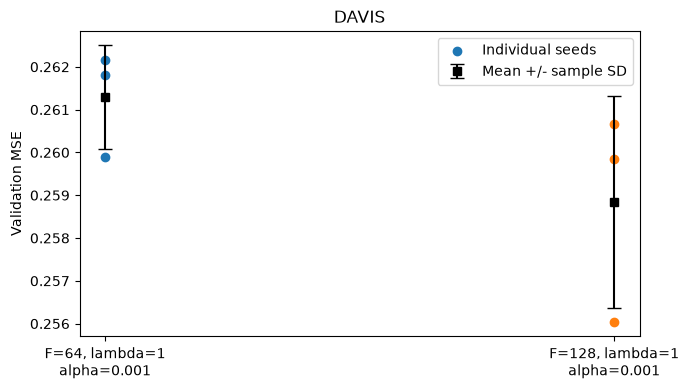

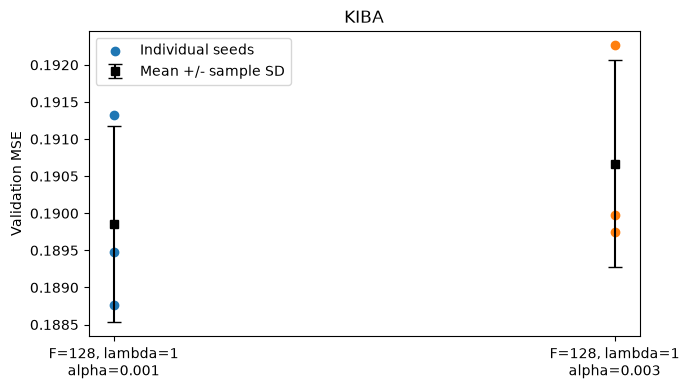

,dataset,n_factors,regularization,learning_rate,seed,parameter_count,train_mse,val_mse,train_val_mse_gap,val_ci,val_hit_at_1,val_hit_at_5,best_epoch,epochs_run,robustness_val_mse_mean,robustness_val_mse_std
0,davis,128,1.000000,0.001000,42,57663,0.026219,0.259842,0.233622,0.873175,0.338235,0.720588,74,84,0.258847,0.002471
1,kiba,128,1.000000,0.001000,42,296313,0.023247,0.188761,0.165513,0.848053,0.690391,0.952211,34,44,0.189855,0.001323


,dataset,reference_factors,reference_alpha,reference_lambda,reference_val_mse,selected_factors,selected_alpha,selected_lambda,selected_seed,selected_val_mse,reduction_absolute,reduction_pct
0,davis,64,0.005000,0.010000,0.271677,128,0.001000,1.000000,42,0.259842,0.011835,4.356204
1,davis,64,0.005000,1.000000,0.267443,128,0.001000,1.000000,42,0.259842,0.007601,2.842103
2,kiba,64,0.005000,0.010000,0.204831,128,0.001000,1.000000,42,0.188761,0.016070,7.845555
3,kiba,64,0.005000,1.000000,0.199242,128,0.001000,1.000000,42,0.188761,0.010481,5.260428


In [6]:
seeds = show_table('stage5_seed_results', METRICS + ['max_epochs', 'extension_applied'])
robustness = show_table('stage5_robustness_summary')
for dataset in ['davis', 'kiba']:
    sub = robustness.loc[robustness.dataset.eq(dataset)]
    fig, ax = plt.subplots(figsize=(7, 4))
    for index, (_, row) in enumerate(sub.iterrows()):
        group = seeds.loc[seeds.dataset.eq(dataset) & seeds.n_factors.eq(row.n_factors)
                          & seeds.regularization.eq(row.regularization)
                          & seeds.learning_rate.eq(row.learning_rate)]
        np.testing.assert_allclose([group.val_mse.mean(), group.val_mse.std(ddof=1)],
                                   [row.val_mse_mean, row.val_mse_std], atol=1e-12, rtol=1e-12)
        ax.scatter(np.full(len(group), index), group.val_mse,
                   label='Individual seeds' if index == 0 else None)
        ax.errorbar(index, row.val_mse_mean, yerr=row.val_mse_std, fmt='s', color='black', capsize=5,
                    label='Mean +/- sample SD' if index == 0 else None)
    ax.set_xticks(range(len(sub)), [f'F={int(r.n_factors)}, lambda={r.regularization:g}\nalpha={r.learning_rate:g}'
                                   for _, r in sub.iterrows()])
    ax.set(title=dataset.upper(), ylabel='Validation MSE')
    ax.legend()
    show_plot(fig)
selected = show_table('final_selection', METRICS + ['robustness_val_mse_mean', 'robustness_val_mse_std'])
references = show_table('reference_comparison')

## 7. Metrics and candidate-count interpretation

- **MSE:** average squared score error; lower is better and it is the primary selection criterion.
  Training MSE is in-sample; different dataset scales prevent direct cross-dataset difficulty claims.
- **CI:** global ordering agreement across validation observations, including cross-drug comparisons.
  Equal actual scores are excluded, tied predictions earn half credit, and no comparable pairs gives NaN.
- **Hit@K:** macro average over ligands, asking whether predicted top-K contains any target tied for
  highest actual affinity. Prediction ties use target string ascending; actual scores are never sorting keys.

Only measured validation candidates are ranked. A singleton always hits; a ligand with at most five
candidates automatically hits at K=5. KIBA has 959 such ligands out of 1,967, including 248 singletons.
Therefore also report Hit@5 restricted to the 1,008 KIBA ligands with more than five candidates,
using the unchanged shared helper. This supplementary metric does not select models.

,dataset,ligands,observed_candidates,min,p25,median,p75,p90,max,mean,singleton_ligands,ligands_at_most_5,ligands_more_than_5
0,davis,68,3865,45,53.000000,57.500000,60.000000,65.000000,79,56.838235,0,0,68
1,kiba,1967,17648,1,2.000000,6.000000,15.000000,21.000000,32,8.972039,248,959,1008


,dataset,candidate_count,ligands,ligand_fraction
0,davis,45,2,0.029412
1,davis,46,2,0.029412
2,davis,47,1,0.014706
3,davis,48,1,0.014706
4,davis,49,1,0.014706
5,davis,50,6,0.088235
6,davis,51,1,0.014706
7,davis,52,2,0.029412
8,davis,53,4,0.058824
9,davis,54,2,0.029412


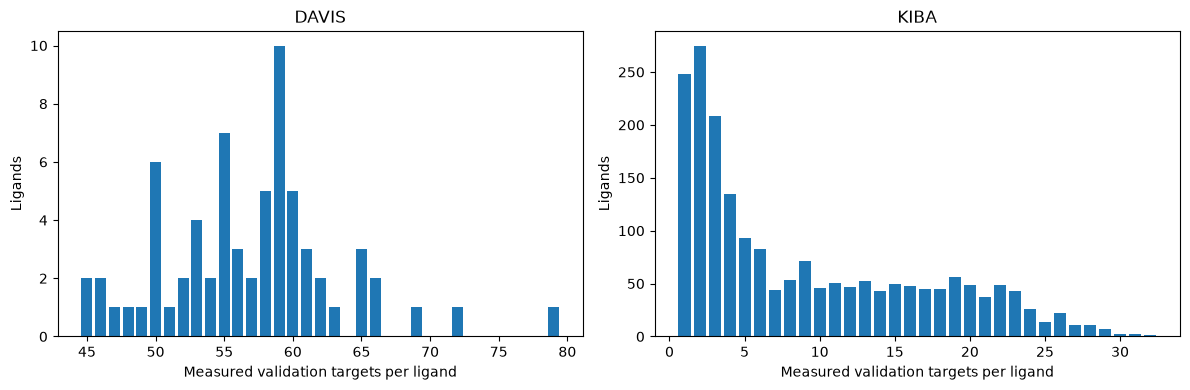

,dataset,val_hit_at_1,val_hit_at_5,val_eligible_ligands,val_hit_at_5_candidates_gt_5,val_eligible_ligands_candidates_gt_5
0,davis,0.338235,0.720588,68,0.720588,68
1,kiba,0.690391,0.952211,1967,0.906746,1008


In [7]:
candidate_summary = show_table('candidate_summary')
counts = show_table('candidate_counts')
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for dataset, ax in zip(['davis', 'kiba'], axes):
    group = counts.loc[counts.dataset.eq(dataset)]
    ax.bar(group.candidate_count, group.ligands)
    ax.set(title=dataset.upper(), xlabel='Measured validation targets per ligand', ylabel='Ligands')
show_plot(fig)
display(selected[['dataset', 'val_hit_at_1', 'val_hit_at_5', 'val_eligible_ligands',
                  'val_hit_at_5_candidates_gt_5', 'val_eligible_ligands_candidates_gt_5']])

## 8. Verify the published checkpoints without fitting

The two `.npz` files are published under `saved_models/`. They retain the exact original bytes and
full-precision parameters. The following cell loads with `allow_pickle=False`, checks model/source/data
hashes, mappings, dimensions and hyperparameters, then verifies exact prediction hashes and recomputed
train/validation metrics. It loads only `train` and `val`, not a test split. Prediction receives ID-only
frames. No external campaign CSV, manifest, plot or backup is needed.

The original 18 correctness tests passed; finite-difference maximum absolute error was 1.059e-10.
All 73 original run states had exact save/reload prediction checks. Here we recheck **only the two
published final states**; the intermediate checkpoints are intentionally not distributed.

In [8]:
from task2.utils.biased_mf import PAIR_KEYS, load_biased_mf, predict_biased_mf
from task2.run_biased_mf import load_selection_splits, evaluate_validation

verified = []
for dataset in ['davis', 'kiba']:
    row = selected.loc[selected.dataset.eq(dataset)].iloc[0]
    relative = f'saved_models/{dataset}_biased_mf.npz'
    path = TASK2 / relative
    assert hashlib.sha256(path.read_bytes()).hexdigest() == EVIDENCE['model_files_sha256'][relative]
    model = load_biased_mf(path)  # Uses np.load(..., allow_pickle=False).
    for key, expected in {'n_factors': 128, 'regularization': 1., 'learning_rate': .001,
                          'seed': 42, 'batch_size': 2048, 'patience': 10}.items():
        assert model[key].item() == expected
    assert int(model['best_epoch']) == int(row.best_epoch) == (74 if dataset == 'davis' else 34)
    provenance = json.loads(model['campaign_provenance'].item())
    for source in ['utils/biased_mf.py', 'utils/evaluation.py']:
        assert hashlib.sha256((TASK2 / source).read_bytes()).hexdigest() == provenance[source]
    parts = load_selection_splits(TASK2, dataset)
    for split, frame in parts.items():
        source = f'data/splits/{dataset}_{split}.csv'
        assert hashlib.sha256((TASK2 / source).read_bytes()).hexdigest() == provenance[source]
        predictions = predict_biased_mf(model, frame[PAIR_KEYS])
        assert hashlib.sha256(predictions.tobytes()).hexdigest() == row[f'{split}_predictions_sha256']
    for name, column in [('drugs', PAIR_KEYS[0]), ('targets', PAIR_KEYS[1])]:
        np.testing.assert_array_equal(model[name], np.sort(parts['train'][column].unique()))
    assert model['drug_factors'].shape == (len(model['drugs']), 128)
    assert model['target_factors'].shape == (len(model['targets']), 128)
    assert float(model['global_mean']) == float(parts['train'].affinity.mean())
    measured = evaluate_validation(model, parts['train'], parts['val'])
    for key, value in measured.items():
        np.testing.assert_allclose(value, row[key], atol=1e-12, rtol=1e-12)
    verified.append({'dataset': dataset, 'best_epoch': int(model['best_epoch']),
                     'prediction_hashes': 'exact match', **measured})
display(pd.DataFrame(verified))
print('Both published checkpoints verified on training and validation only; no training performed.')

,dataset,best_epoch,prediction_hashes,train_mse,val_mse,val_ci,val_hit_at_1,val_hit_at_5,val_eligible_ligands,val_hit_at_5_candidates_gt_5,val_eligible_ligands_candidates_gt_5
0,davis,74,exact match,0.026219,0.259842,0.873175,0.338235,0.720588,68,0.720588,68
1,kiba,34,exact match,0.023247,0.188761,0.848053,0.690391,0.952211,1967,0.906746,1008


Both published checkpoints verified on training and validation only; no training performed.


## 9. Audit, reproduction and limitations

The notebook metadata contains full-precision recorded tables, complete 73-run learning traces,
source CSV hashes, checkpoint hashes and the source commit for Jiaxin's rows. Python/NumPy/pandas/Matplotlib
plus Jupyter are needed to execute it. SHA checks tie the published final states to the fixed data and
unchanged core/evaluation code. This snapshot packaging is not another training run or statistical test.

To run software tests from the repository root:
```bash
mkdir -p /tmp/opencode
OPENBLAS_NUM_THREADS=1 .venv/bin/python -B -m unittest discover -s task2/tests -p 'test_biased_mf.py' -v
```
To view/reexecute the saved tables, plots and model checks:
```bash
.venv/bin/jupyter notebook task2/biased_mf.ipynb
```
Deliberate retraining is a separate action using `run_biased_mf.py --stage ... --output-dir ...`;
follow the README/protocol. Never run it merely to view these results. The CLI full-evidence verifier
still requires its separate local aggregate files; this notebook is the published standalone verification route.

Limitations: repeated selection on one validation split, only three seeds, budget-limited strong-penalty
core cells, conditional rate refinement, nonconvex optimization, ID-only warm-start scope, global CI,
and candidate-set effects on Hit@K. No final-test result is reported.

Remaining work: review the combined comparison with Jiaxin, agree on frozen final models, conduct the
planned final evaluation without test-driven tuning, complete three ligand case studies per dataset,
and prepare the report/presentation. Existing teammate notebooks have historical test outputs; this
notebook copies only their training/validation columns and never uses those test results for selection.

In [9]:
inventory = show_table('all_physical_runs',
                       ['dataset', 'n_factors', 'regularization', 'learning_rate', 'seed', 'max_epochs',
                        'train_mse', 'val_mse', 'best_epoch', 'epochs_run', 'status', 'origin'])
display(pd.DataFrame([{'source_file': name, 'sha256': value}
                      for name, value in EVIDENCE['source_files_sha256'].items()]))
print('Historical verification record:', EVIDENCE['historical_verification'])
print('Recorded correctness checks:', EVIDENCE['test_results'])

,dataset,n_factors,regularization,learning_rate,seed,max_epochs,train_mse,val_mse,best_epoch,epochs_run,status,origin
0,davis,128,1.000000,0.001000,123,100,0.029494,0.256034,71,81,ok,new_configuration
1,davis,128,1.000000,0.001000,2026,100,0.021422,0.260665,81,91,ok,new_configuration
2,davis,128,1.000000,0.001000,42,100,0.026219,0.259842,74,84,ok,new_configuration
3,davis,128,1.000000,0.003000,42,100,0.028465,0.263022,25,35,ok,new_configuration
4,davis,128,0.000000,0.005000,42,100,0.023977,0.268324,14,24,ok,new_configuration
5,davis,128,0.010000,0.005000,42,100,0.024080,0.268317,14,24,ok,new_configuration
6,davis,128,0.100000,0.005000,42,100,0.019729,0.267810,15,25,ok,new_configuration
7,davis,128,10.000000,0.005000,42,100,0.185087,0.302430,84,94,ok,new_configuration
8,davis,128,1.000000,0.005000,42,100,0.031364,0.264120,15,25,ok,new_configuration
9,davis,128,1.000000,0.010000,42,100,0.023185,0.268846,9,19,ok,new_configuration


,source_file,sha256
0,results/biased_mf/data_integrity.csv,403df0d182b578c18160a1dc1e4c7a22db41bbebc84a78...
1,results/biased_mf/candidate_summary.csv,9c54097429e17627de3d19dbcc01edb420f799847be29f...
2,results/biased_mf/candidate_counts.csv,55dd3152c3769b4e25a0f5005050e2578dfe97f18cefa6...
3,results/biased_mf/stage1_capacity.csv,c3010ca3c608350a1836ea0a76c623c8ddc517bf9a9417...
4,results/biased_mf/stage3_interaction.csv,5e7a05dd2d2e61e994699ae1908c44ceca0d6ed5fd9c02...
5,results/biased_mf/stage3_best_lambda_per_f.csv,97447081142266e3a43cff14261038472e23f4ee6ab427...
6,results/biased_mf/stage3_best_f_per_lambda.csv,414373aa01afdadf445c571060186912f9af8227750825...
7,results/biased_mf/stage4_candidates.csv,d3203e7d687c482feb0fc8e01db02fbeea87de8b7296d6...
8,results/biased_mf/stage4_rates.csv,c674c8217fc9190b2792ba53d261db9b8e0df7e7829816...
9,results/biased_mf/stage5_seed_results.csv,ba407c67da6fb6b0ceac00bc694789a6ba94be86e3c416...


Historical verification record: {'physical_fits': 73, 'successful': 73, 'failures': 0, 'extended_cap_fits': 3, 'checkpoint_and_prediction_reloads': 'exact equality for every successful run on train and validation', 'fingerprints_match': True, 'test_splits_loaded': False}
Recorded correctness checks: {'original_tests_passed': 18, 'max_gradient_absolute_error': 1.059e-10, 'gradient_atol': 1e-08, 'gradient_rtol': 1e-06, 'batch_l2_atol': 1e-15, 'batch_l2_rtol': 1e-13}
